## Utils

In [1]:
import json
import os
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy import stats
import pandas as pd
import seaborn as sns

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['STIXGeneral']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['pdf.fonttype'] = 42

# Run notebook from analysis/ or set explicitly; path relative to cwd
RESULTS_DIR = (Path("..") / "results").resolve()


# Map full model paths to simplified names (like configs: dinov2_14, clip_16, etc.)
def simplify_model_name(full_name):
    """Convert e.g. facebook/dinov2-base -> dinov2_14, openai/clip-vit-base-patch32 -> clip_32"""
    m = full_name.lower()
    if "dinov2" in m or "dinov2-base" in m:
        return "DINOv2"
    if "dino-vitb" in m:
        return "DINO"
    if "vit-mae" in m or "mae" in m:
        return "MAE"
    if "google" in m:
        if "patch32" in m or "patch 32" in m:
            return "ImageNet 32"
        return "ImageNet 16"
    if "clip" in m:
        if "patch32" in m or "patch 32" in m:
            return "CLIP 32"
        return "CLIP 16"
    return full_name.replace("/", "_")


def load_gestalt_results(results_dir=None, dataset="blobs"):
    """
    Load all *_gestalt_eval.json files from the results directory.
    Returns: dict[model_name, dict[layer, results_dict]]
    """

    if dataset == "blobs":
        json_filename = "gestalt_eval.json"
    elif dataset == "curves":
        json_filename = "curves_gestalt_eval.json"
    else:
        raise ValueError("Dataset has to be either blobs or curves")

    results_dir = Path(results_dir or RESULTS_DIR)
    data = defaultdict(dict)
    
    for org_dir in Path(results_dir).iterdir():
        if not org_dir.is_dir():
            continue
        for model_dir in org_dir.iterdir():
            if not model_dir.is_dir():
                continue
            model_name = f"{org_dir.name}/{model_dir.name}"
            for layer_dir in model_dir.iterdir():
                if not layer_dir.is_dir():
                    continue
                try:
                    layer = int(layer_dir.name)
                except ValueError:
                    continue
                json_path = layer_dir / json_filename
                if json_path.exists():
                    with open(json_path, "r") as f:
                        data[model_name][layer] = json.load(f)
    
    return dict(data)


## Per Layer Probe Accuracy

In [2]:
def plot_per_layer_accuracy(results_dir=None, dataset="curves", subplots_per_model=True):
    """
    Plot per-layer test accuracy for each model, compared to orientation and location accuracies.
    
    For each model: x=layer, y=accuracy; lines for base (test), orientation, location.
    subplots_per_model: if True, one subplot per model; else all models on one plot.
    """
    data = load_gestalt_results(results_dir, dataset=dataset)
    model_list = sorted(data.items())
    n = len(model_list)
    
    if subplots_per_model and n > 1:
        ncols = min(n, 3)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
        axes = axes.flatten()
        for idx in range(n, len(axes)):
            axes[idx].set_visible(False)
    else:
        fig, ax = plt.subplots(figsize=(10, 6))
        axes = [ax]
    
    for idx, (model_name, layer_results) in enumerate(model_list):
        a = axes[idx] if subplots_per_model and n > 1 else axes[0]
        layers = sorted(layer_results.keys())
        base_acc = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        orient_acc = [layer_results[l]["standard"]["orientation"]["accuracy"] for l in layers]
        loc_acc = [layer_results[l]["standard"]["location"]["accuracy"] for l in layers]
        
        suff = f" ({model_name})" if not (subplots_per_model and n > 1) else ""
        a.plot(layers, base_acc, "o-", label=f"Test{suff}", linewidth=2, markersize=6)
        a.plot(layers, orient_acc, "s--", label=f"Orientation{suff}", alpha=0.8, markersize=4)
        a.plot(layers, loc_acc, "^-.", label=f"Location{suff}", alpha=0.8, markersize=4)
        
        a.set_xlabel("Layer")
        a.set_ylabel("Accuracy")
        if subplots_per_model and n > 1:
            short_name = simplify_model_name(model_name)
            a.set_title(short_name)
        else:
            a.set_title("Per-layer Probe Accuracy")
        a.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
        a.grid(True, alpha=0.3)
        a.axhline(0.5, color="gray", linestyle=":", alpha=0.5)
    
    plt.suptitle(f"{dataset.capitalize()} Probe Performance By Layer")
    plt.tight_layout()
    return axes[0] if len(axes) == 1 else axes


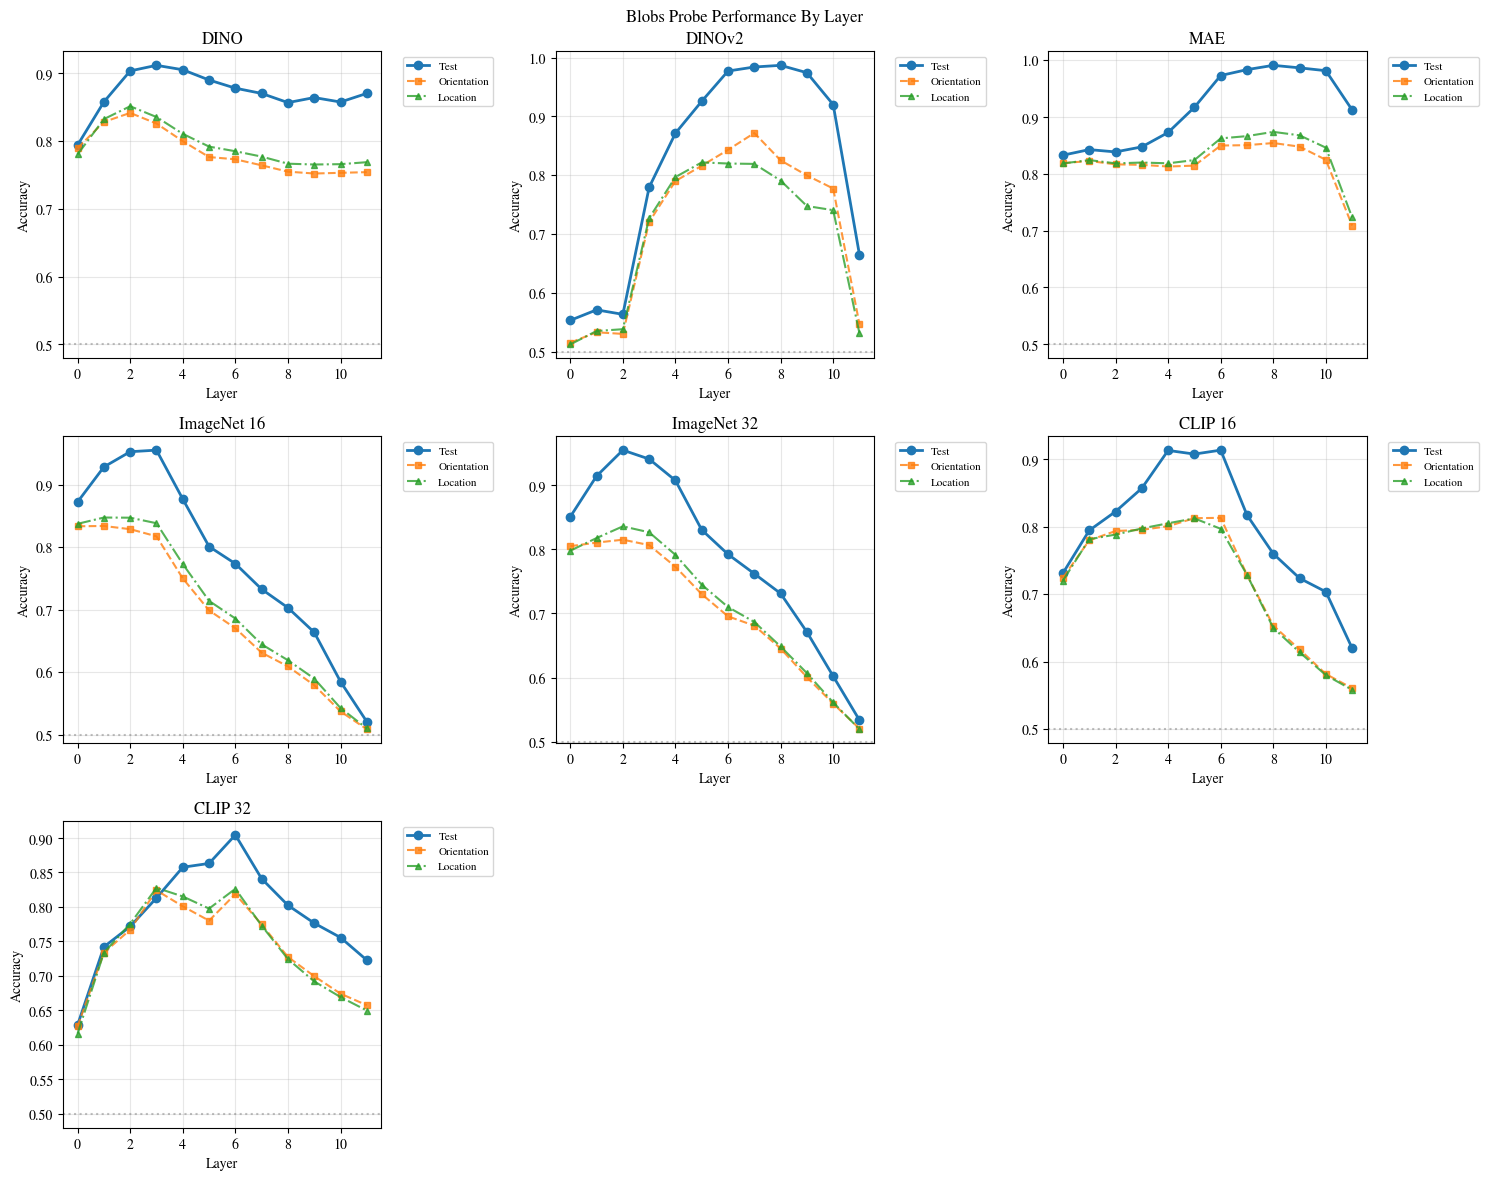

In [3]:
# Plot 1: Per-layer test accuracy vs orientation and location
plot_per_layer_accuracy(dataset="blobs")
plt.show()

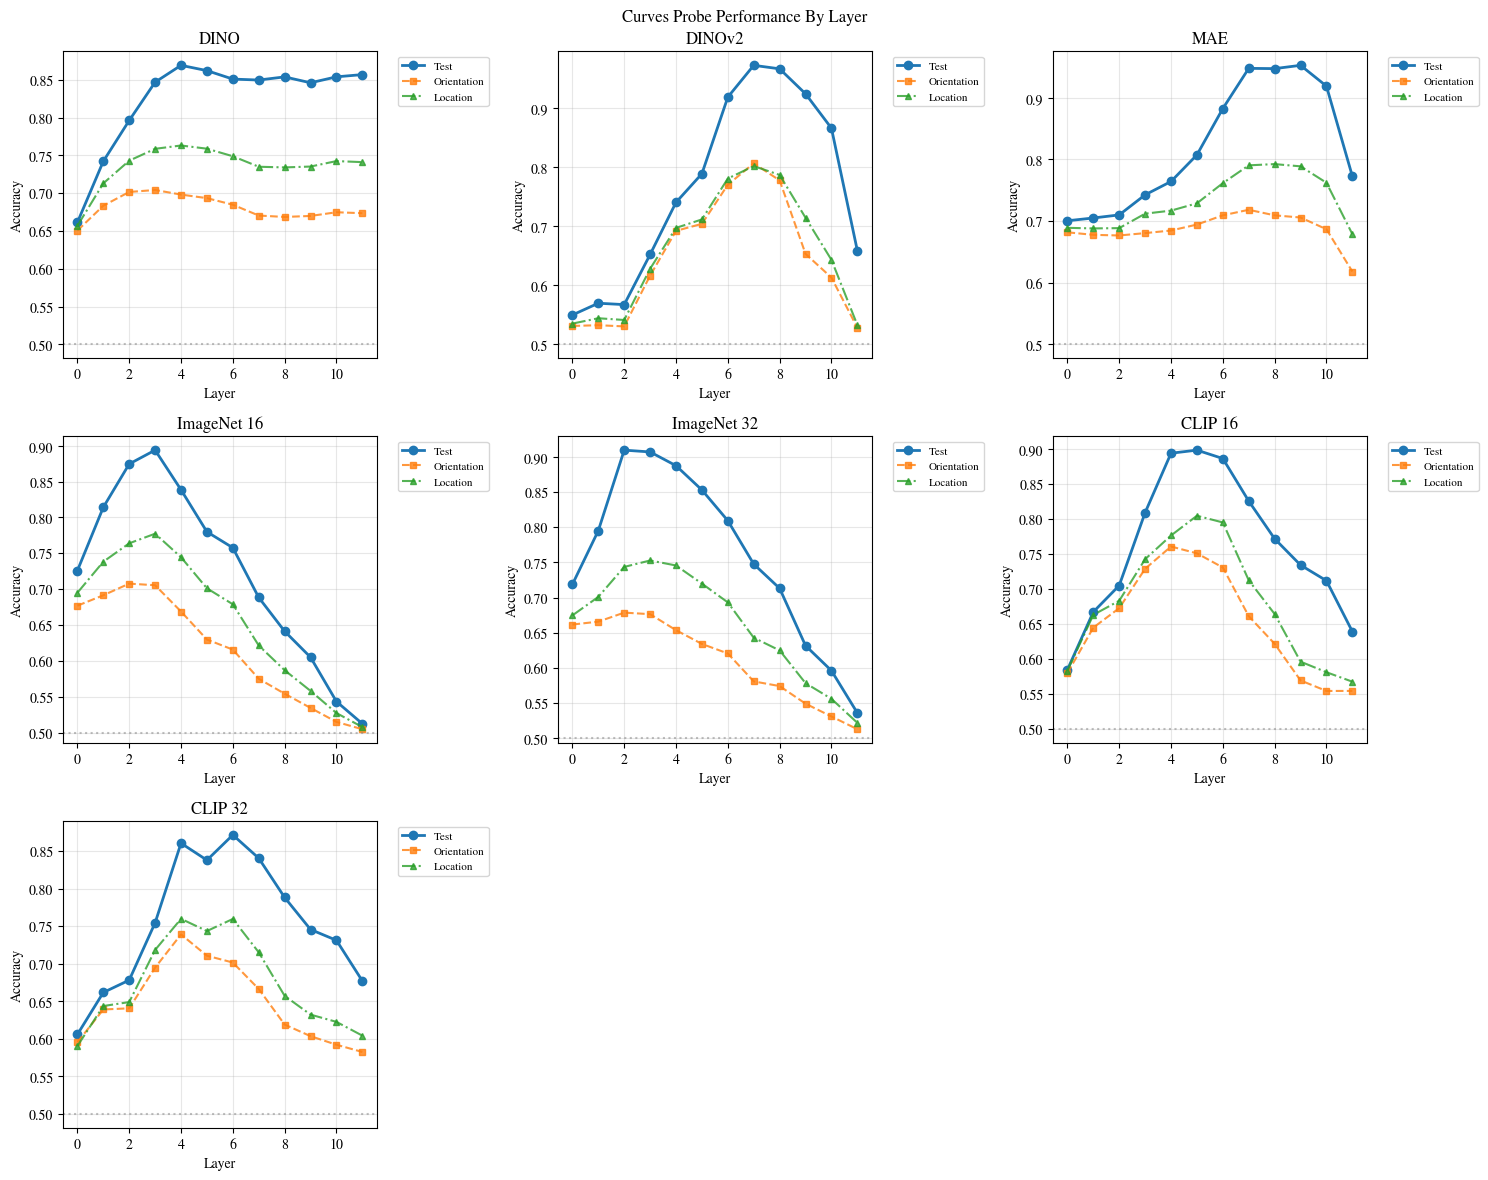

In [4]:
plot_per_layer_accuracy(dataset="curves")
plt.show()

## Aggregate Probe Delta 

In [5]:
def plot_average_scramble_delta_by_layer(datasets, results_dir=None, models=None, ax=None, figsize=(7, 5)):
    """
    Plot per-layer delta across models, where
    delta(layer, model) = base_accuracy - max(orientation_accuracy, location_accuracy).

    Main line: mean delta across models.
    Shaded band: min-to-max delta across models at each layer.
    """

    colors = ["#B0351C", "#6641E1"]
    for i, dataset in enumerate(datasets):
        data = load_gestalt_results(results_dir, dataset=dataset)
        if models:
            data = {m: data[m] for m in models if m in data}

        if not data:
            raise ValueError('No model data available for plotting.')

        deltas_by_model = {}
        all_layers = set()

        for model_name, layer_results in sorted(data.items()):
            model_deltas = {}
            for layer in sorted(layer_results.keys()):
                res = layer_results[layer]["standard"]
                base = res["base"]["accuracy"]
                orient = res["orientation"]["accuracy"]
                loc = res["location"]["accuracy"]
                model_deltas[layer] = base - max(orient, loc)
                all_layers.add(layer)
            deltas_by_model[model_name] = model_deltas

        layers = sorted(all_layers)
        delta_matrix = []
        for model_name in sorted(deltas_by_model.keys()):
            row = [deltas_by_model[model_name].get(layer, np.nan) for layer in layers]
            delta_matrix.append(row)

        delta_matrix = np.asarray(delta_matrix, dtype=float)
        mean_delta = np.nanmean(delta_matrix, axis=0)
        min_delta = np.nanmin(delta_matrix, axis=0)
        max_delta = np.nanmax(delta_matrix, axis=0)

        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)

        ax.fill_between(
            layers,
            min_delta,
            max_delta,
            color=colors[i],
            alpha=0.18,
        )
        ax.plot(layers, mean_delta, "o-", color=colors[i], linewidth=2.5, markersize=6, label=dataset.capitalize())

    def multiply_by_ten(tick_value, position):
        # tick_value is the actual data value at the tick position (e.g., 0, 20, 40)
        # position is the index of the tick
        new_value = tick_value * 100
        return f'{new_value:.1f}' # Format as a string with no decimals

    # 2. Apply the formatter to the y-axis
    # The FuncFormatter maps the original tick values to the new multiplied labels
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(multiply_by_ten))

    ax.set_xlabel("Layer", fontsize=13)
    ax.set_ylabel(r"$\Delta$ Probe Accuracy (Test $-$ Control)", fontsize=13)
    ax.set_title(fr"$\Delta$ Probe Accuracy", fontsize=15)
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
    ax.legend(fontsize=15)

    plt.tight_layout()
    return fig


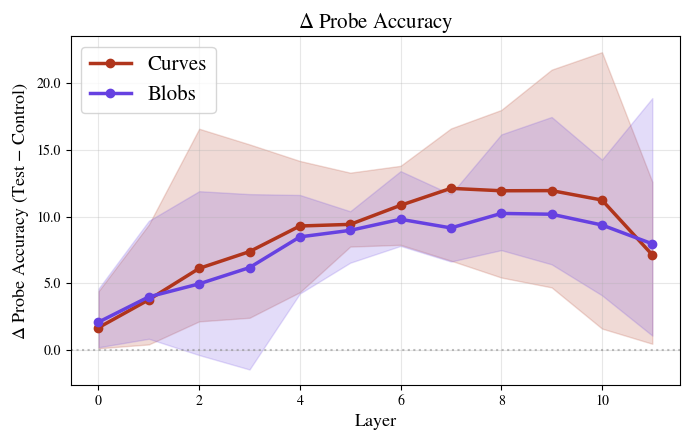

In [ ]:
fig = plot_average_scramble_delta_by_layer(datasets=["curves", "blobs"], figsize=(7, 4.5))
plt.show()
fig.savefig(
    "../../figs/probe_deltas.pdf",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1,
    transparent=True,  # no background fill
    format="pdf"
)

## Latex Table

In [ ]:
def build_max_probe_accuracy_latex_table(dataset="curves", results_dir=None, models=None):
    """
    Build a LaTeX table with columns:
      Model | Max Probe Test Acc. (Base, Scrambled)
    where Scrambled is max over orientation/location at each layer, then max over layers.
    """
    data = load_gestalt_results(results_dir, dataset)
    if models:
        data = {m: data[m] for m in models if m in data}

    if not data:
        raise ValueError('No model data available for table.')

    rows = []
    for model_name, layer_results in sorted(data.items()):
        layers = sorted(layer_results.keys())
        base_vals = [layer_results[l]["standard"]["base"]["accuracy"] for l in layers]
        scrambled_vals = [
            max(
                layer_results[l]["standard"]["orientation"]["accuracy"],
                layer_results[l]["standard"]["location"]["accuracy"],
            )
            for l in layers
        ]

        max_base = max(base_vals) * 100.0
        max_scrambled = max(scrambled_vals) * 100.0
        rows.append((simplify_model_name(model_name), max_base, max_scrambled))

    lines = []
    lines.append(r'\begin{table}[t]')
    lines.append(r'\centering')
    lines.append(r'\begin{tabular}{lcc}')
    lines.append(r'\toprule')
    lines.append(r'Model & \multicolumn{2}{c}{Max Probe Test Acc.} \\ ')
    lines.append(r' & Base & Scrambled \\')
    lines.append(r'\midrule')

    for model_label, max_base, max_scrambled in rows:
        lines.append(f'{model_label} & {max_base:.1f}\% & {max_scrambled:.1f}\% \\ ')

    lines.append(r'\bottomrule')
    lines.append(r'\end{tabular}')
    lines.append(r'\caption{Maximum probe test accuracy by model for base and scrambled conditions.}')
    lines.append(r'\label{tab:max_probe_test_acc}')
    lines.append(r'\end{table}')

    return '\n'.join(lines)


<>:40: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:40: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:40: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:40: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
/tmp/ipykernel_696873/1295343124.py:40: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
  lines.append(f'{model_label} & {max_base:.1f}\% & {max_scrambled:.1f}\% \\ ')
/tmp/ipykernel_696873/1295343124.py:40: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not wo

In [ ]:
# Plot/Table 4: LaTeX table for max base vs scrambled probe test accuracy
latex_table = build_max_probe_accuracy_latex_table(dataset="curves")
print(latex_table)


\begin{table}[t]
\centering
\begin{tabular}{lcc}
\toprule
Model & \multicolumn{2}{c}{Max Probe Test Acc.} \\ 
 & Base & Scrambled \\
\midrule
DINO & 91.2\% & 85.1\% \ 
DINOv2 & 98.7\% & 87.2\% \ 
MAE & 99.0\% & 87.3\% \ 
ImageNet 16 & 95.5\% & 84.7\% \ 
ImageNet 32 & 95.5\% & 83.6\% \ 
CLIP 16 & 91.3\% & 81.3\% \ 
CLIP 32 & 90.4\% & 82.8\% \ 
\bottomrule
\end{tabular}
\caption{Maximum probe test accuracy by model for base and scrambled conditions.}
\label{tab:max_probe_test_acc}
\end{table}


## Selective Ablations

In [7]:
def get_most_selective_ablation_df(dataset):
    data = load_gestalt_results(None, dataset)

    model_names = []
    test_decrement = []
    location_decrement = []
    orientation_decrement = []

    for model_name, layer_results in sorted(data.items()):
        best_selectivity = -np.inf
        best_test_dec = None
        best_location_dec = None
        best_orientation_dec = None

        for layer in sorted(layer_results.keys()):
            res = layer_results[layer]

            test_acc = res['standard']['base']['accuracy']
            test_ablation_acc = res['ablation']['base']['accuracy']
            test_dec = test_acc - test_ablation_acc

            orientation_acc = res['standard']['orientation']['accuracy']
            orientation_ablation_acc = res['ablation']['orientation']['accuracy']
            orientation_dec = orientation_acc - orientation_ablation_acc      

            location_acc = res['standard']['location']['accuracy']
            location_ablation_acc = res['ablation']['location']['accuracy']
            location_dec = location_acc - location_ablation_acc

            selectivity = test_dec - max(orientation_dec, location_dec)

            if selectivity > best_selectivity:
                best_selectivity = selectivity
                best_test_dec = test_dec
                best_orientation_dec = orientation_dec
                best_location_dec = location_dec

        model_names.append(simplify_model_name(model_name))
        test_decrement.append(best_test_dec)
        location_decrement.append(best_location_dec)
        orientation_decrement.append(best_orientation_dec)


    dataframe = pd.DataFrame.from_dict(
        {
            "Model": model_names + model_names + model_names,
            "Dataset": (["Test"] * len(test_decrement)) + (["Location Control"] * len(location_decrement)) + (["Orientation Control"] * len(orientation_decrement)),
            "Ablation": test_decrement + location_decrement + orientation_decrement
        }
    )

    return dataframe


def plot_most_selective_ablation():
    """
    Single grouped bar chart by model:
      - Single ablation that hurt test objects more than control (scrambled/location) objects
    """
    curves_df = get_most_selective_ablation_df("curves")
    blobs_df = get_most_selective_ablation_df("blobs")

    palette = {
        "Test": "#03BEB2",
        "Location Control": "#D20000",
        "Orientation Control": "#860000"
    }

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    # Left subplot
    sns.barplot(
        data=curves_df,
        x="Model",
        y="Ablation",
        hue="Dataset",
        palette=palette,
        edgecolor="black",
        linewidth=1,
        ax=axes[0]
    )
    axes[0].set_title("Curves")

    sns.barplot(
        data=blobs_df,
        x="Model",
        y="Ablation",
        hue="Dataset",
        palette=palette,
        edgecolor="black",
        linewidth=1,
        ax=axes[1]
    )
    axes[1].set_title("Blobs")

    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend_.remove()
    axes[1].legend_.remove()

    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=1,
        frameon=True,
        bbox_to_anchor=(0.91, .85)
    )

    plt.ylim(bottom=0.0)
    fig.suptitle("Most Selective Ablations Per Model")
    plt.tight_layout()

    return 

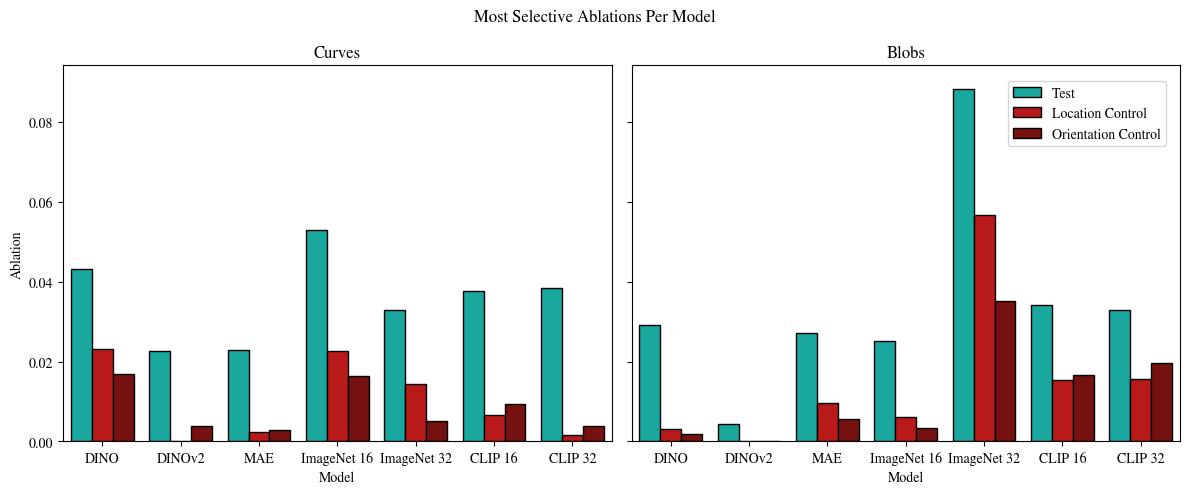

In [8]:
plot_most_selective_ablation()

## Per Layer Selectivity with Controls

In [ ]:
def plot_ablation_selectivity_by_layer(dataset="curves", control_dataset="orientation", control_band="minmax"):
    """
    Per-layer selectivity (test ablation performance decrement − {Orientation ablation, Location ablation}) — one subplot per model.
    Test ablation line + control band (iqr, or minmax) per layer.
    Requires ablation/controls on base, orientation, location.
    """
    data = load_gestalt_results(None, dataset)
    model_list = sorted(data.items())
    n = len(model_list)
    ncols = min(n, 3)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
    axes = axes.flatten()
    for idx in range(n, len(axes)):
        axes[idx].set_visible(False)
    for idx, (model_name, layer_results) in enumerate(model_list):
        ax = axes[idx]
        short_name = simplify_model_name(model_name)
        layers = sorted(layer_results.keys())
        target_selectivity = []
        ctrl_lower, ctrl_upper = [], []
        for l in layers:
            res = layer_results[l]

            if control_dataset=="orientation":
                ctrl_acc = res["standard"]["orientation"]["accuracy"]
                ctrl_dec = ctrl_acc - res["ablation"]["orientation"]["accuracy"]
                ctrl_ablations = res["controls"]["orientation"]["accuracy"]

            elif control_dataset=="location":
                ctrl_acc = res["standard"]["location"]["accuracy"]
                ctrl_dec = ctrl_acc - res["ablation"]["location"]["accuracy"]
                ctrl_ablations = res["controls"]["location"]["accuracy"]
            else:
                raise ValueError("Control Dataset must be orientation or location")

            base = res["standard"]["base"]["accuracy"]
            obj_dec = base - res["ablation"]["base"]["accuracy"]
            target_selectivity.append(obj_dec - ctrl_dec)

            ctrl_base = res["controls"]["base"]["accuracy"]

            # Selectivity scores from ablating random subsets of heads
            ctrl_sels = [(base - cb) - (ctrl_acc - ca)
                         for cb, ca in zip(ctrl_base, ctrl_ablations)]
            arr = np.array(ctrl_sels)
            if control_band == "IQR":
                q25, q75 = np.percentile(arr, [25, 75])
                ctrl_lower.append(q25)
                ctrl_upper.append(q75)
            elif control_band == "minmax":
                ctrl_lower.append(np.min(arr))
                ctrl_upper.append(np.max(arr))
            else:
                raise ValueError("Control band should be IQR or minmax")
        ax.fill_between(layers, ctrl_lower, ctrl_upper, alpha=0.2, color="gray", label=f"Control ablations ({control_band})")
        ax.plot(layers, target_selectivity, "o-", color="C0", linewidth=2, markersize=6, label="Target Ablation")
        ax.set_xlabel("Layer")
        ax.set_ylabel("Selectivity")
        ax.set_title(short_name)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)

    plt.suptitle(fr"{dataset.capitalize()} Dataset Ablation Selectivity ($\Delta$ Test - $\Delta$ Scrambled {control_dataset.capitalize()}) Per Layer")
    plt.tight_layout()
    return axes


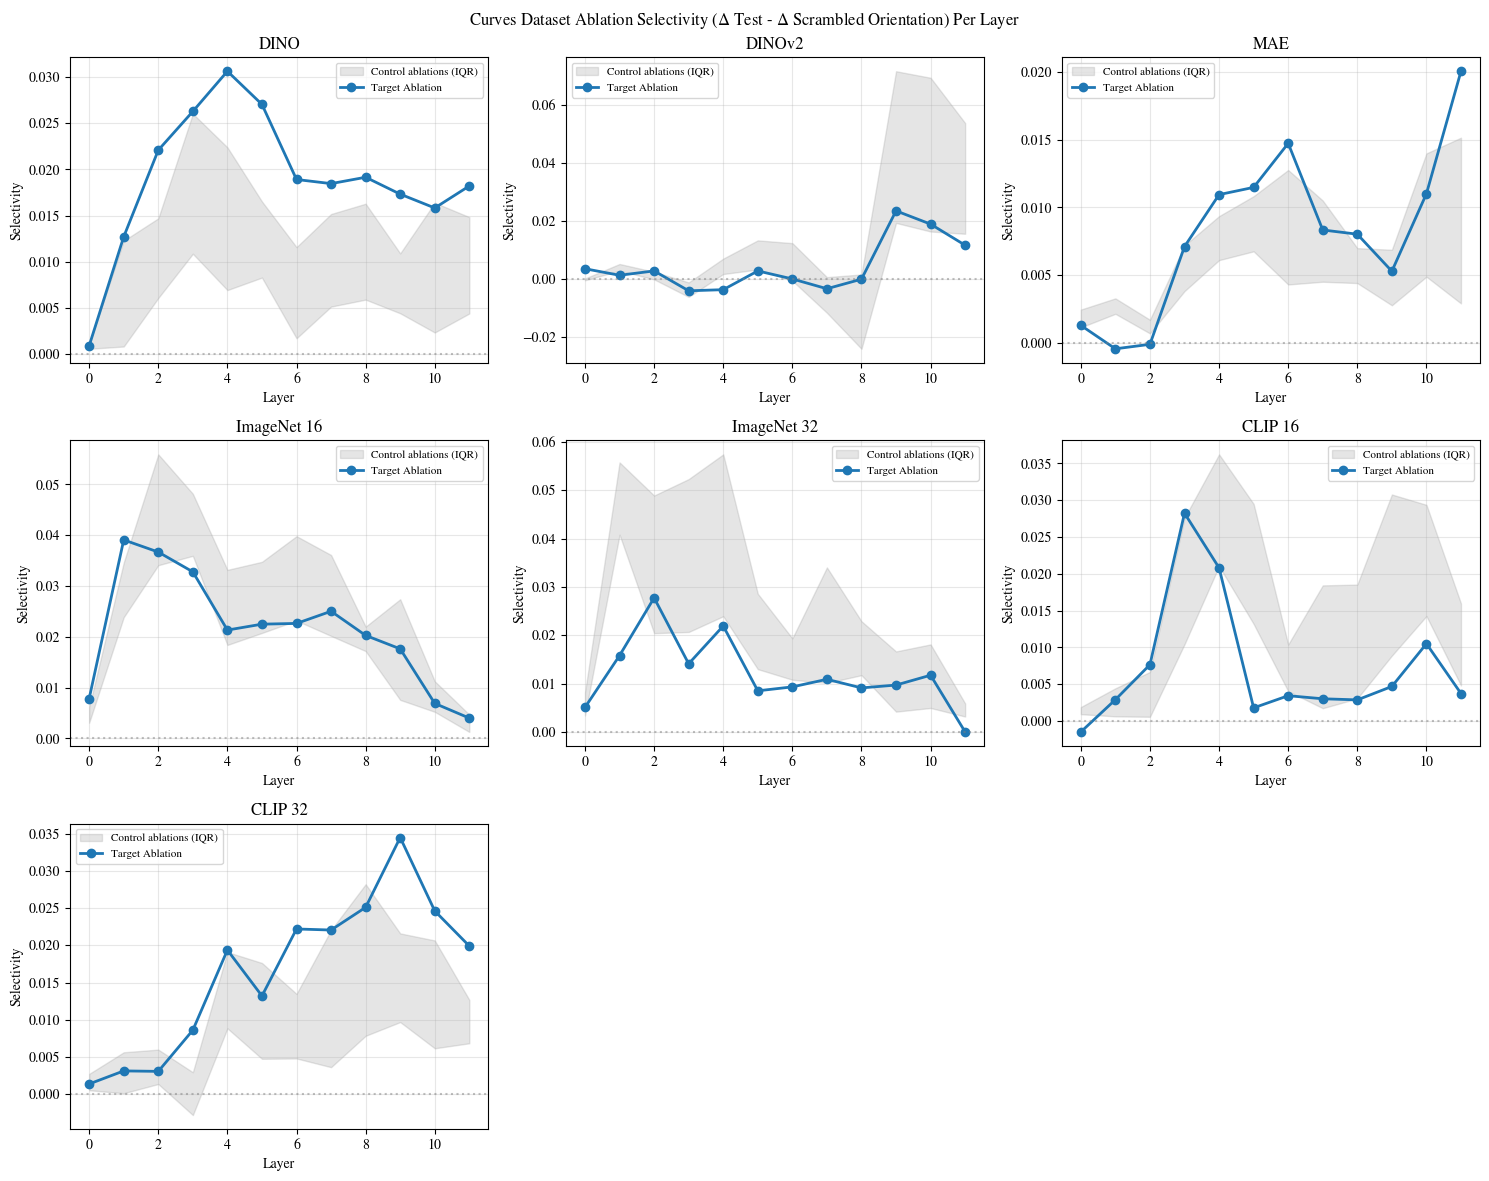

In [29]:
# Plot: Ablation selectivity by layer (one subplot per model, like plot_ablation_decrement_by_layer)
# control_band: "iqr", "minmax", or "std"
plot_ablation_selectivity_by_layer(dataset="curves", control_dataset="orientation", control_band="IQR")
plt.show()